In [1]:
from src import assemble_nodes
from src.orientation import get_angles, _correlate_angles, _make_rotating_masks
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize
from mpl_toolkits.axes_grid1 import ImageGrid
from src.graph import Tree, ImageSegmentation
import torch
import os
from torchvision.io import read_image

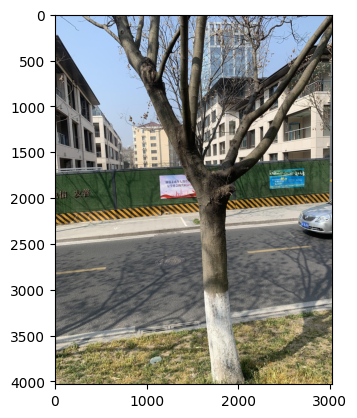

In [2]:
img = read_image("resource/branch_dataset/JPEGImages/Albizia julibrissin_branch_1 (20).jpg")
plt.imshow(img.permute(1, 2, 0) )

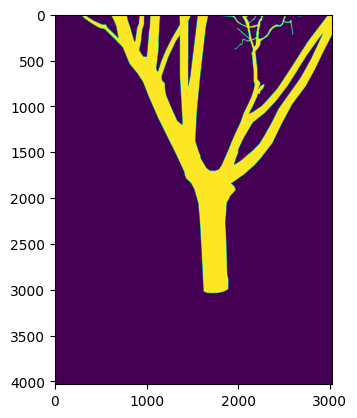

In [3]:
mask_orig = cv.imread("resource/branch_dataset/SegmentationClass/Albizia julibrissin_branch_1 (20).png")
mask = cv.cvtColor(mask_orig, cv.COLOR_RGB2GRAY)
ret, mask = cv.threshold(mask, 0, 255, cv.THRESH_OTSU)
plt.imshow(mask)

In [4]:
cnn = ImageSegmentation(kernel_size=3)
checkpoint = torch.load(os.path.join("model_checkpoints", f"checkpoint_nov_14_1chn_out_BCE.tar"))
cnn.load_state_dict(checkpoint["model_state_dict"])
cnn.eval()

tree_model = Tree(img, cnn)
print(f"Found {len(tree_model.edges)} branches in image")

c:\Users\wyatt\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\transforms\functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


Found 291 branches in image


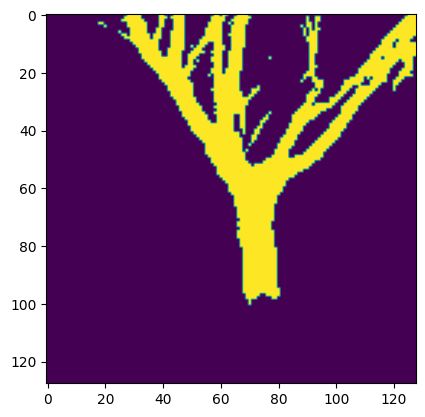

In [5]:
plt.imshow(tree_model._mask)

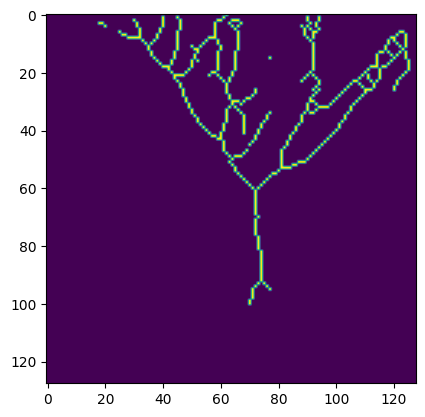

In [6]:
skel = tree_model._skel.copy()
plt.imshow(skel)

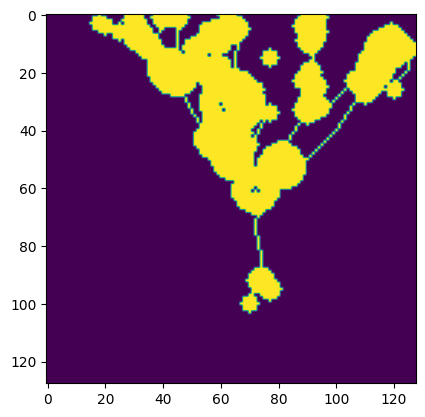

In [7]:
for node in tree_model.nodes:
    cv.circle(skel, (node.pixel_coord[1], node.pixel_coord[0]), node.width//2, color=(255, 0, 0), thickness=5)
plt.imshow(skel)

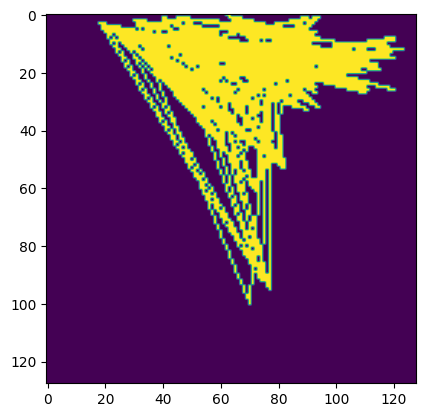

In [8]:
est = tree_model.reconstruct_mask()
plt.imshow(est)